In [ ]:
from google.colab import userdata
print('Key found, length:', len(userdata.get('ROBOFLOW_API_KEY')))

Key found, length: 31


In [ ]:
!pip install -q inference-sdk opencv-python-headless
import cv2, numpy as np, matplotlib.pyplot as plt
from base64 import b64decode
from IPython.display import display, Javascript
from google.colab import userdata
from google.colab.output import eval_js
from inference_sdk import InferenceHTTPClient

API_KEY = userdata.get('ROBOFLOW_API_KEY')
MODEL_ID = "PASTE_MODEL_URL_HERE"   # copy from the model page after training
THRESHOLD = 0.87                    # Roboflow's "Optimal Confidence"; adjust after testing

client = InferenceHTTPClient(api_url="https://serverless.roboflow.com", api_key=API_KEY)

def take_photo(filename='webcam.jpg', quality=0.9):
    display(Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => capture.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    '''))
    data = eval_js('takePhoto({})'.format(quality))
    with open(filename, 'wb') as f:
        f.write(b64decode(data.split(',')[1]))
    return filename

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_eye.xml')

def crop_face(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    H, W = gray.shape
    min_side = int(0.15 * min(H, W))
    faces = face_cascade.detectMultiScale(gray, 1.1, 8, minSize=(min_side, min_side))
    for (x, y, w, h) in sorted(faces, key=lambda f: -f[2] * f[3]):
        roi = gray[y:y + h, x:x + w]
        eyes = eye_cascade.detectMultiScale(roi, 1.1, 5, minSize=(int(0.1 * w), int(0.1 * w)))
        if len(eyes) >= 1:
            m = int(0.25 * w)
            crop = img[max(y - m, 0):y + h + m, max(x - m, 0):x + w + m]
            return cv2.resize(crop, (224, 224))
    return None

def recognise(path):
    img = cv2.imread(path)
    face = crop_face(img)
    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.title('Camera photo')
    if face is None:
        plt.show()
        print('DECISION: No face found. Look at the camera, add light, and retake the photo.')
        return
    cv2.imwrite('face.jpg', face)
    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(face, cv2.COLOR_BGR2RGB));

<IPython.core.display.Javascript object>

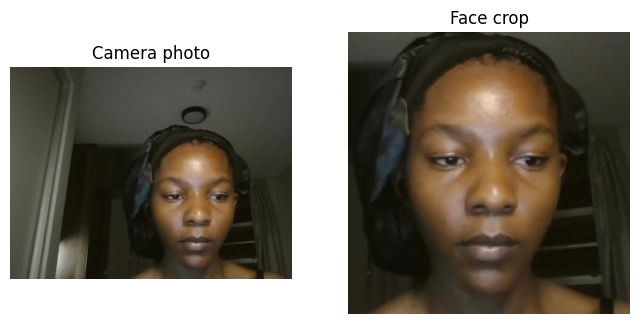

Camera and face detection work.


In [4]:
take_photo('test.jpg')
img = cv2.imread('test.jpg')
face = crop_face(img)
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.title('Camera photo')
if face is None:
    plt.show(); print('No face found. Add light and fill more of the frame.')
else:
    plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(face, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.title('Face crop')
    plt.show(); print('Camera and face detection work.')

Client ready and authorized!


<IPython.core.display.Javascript object>

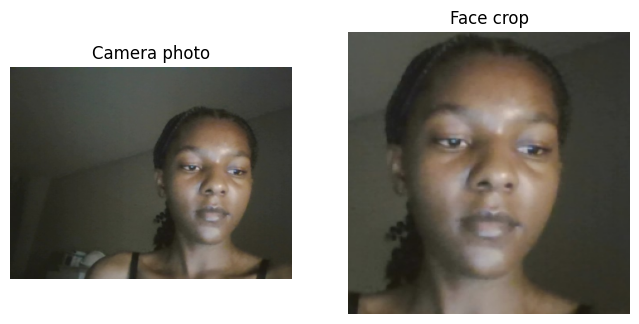

✅ Welcome, hilma! (Confidence: 83.7%)

Press Enter to try again, or type q to stop: q


In [21]:
!pip install -q inference-sdk opencv-python-headless
import cv2, numpy as np, matplotlib.pyplot as plt
from base64 import b64decode
from IPython.display import display, Javascript
from google.colab.output import eval_js
from inference_sdk import InferenceHTTPClient

# ==========================================
# 1. SETUP CREDENTIALS & MODEL ID
# ==========================================
API_KEY = "I0DokXNM9fGnnk5BkzTF"
MODEL_ID = "faces_v4/1"
THRESHOLD = 0.80

# Configure for Roboflow Classification endpoint
client = InferenceHTTPClient(
    api_url="https://classify.roboflow.com",
    api_key=API_KEY
)

print("Client ready and authorized!")

# ==========================================
# 2. WEBCAM CAPTURE FUNCTION
# ==========================================
def take_photo(filename='webcam.jpg', quality=0.9):
    display(Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => capture.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    '''))
    data = eval_js('takePhoto({})'.format(quality))
    with open(filename, 'wb') as f:
        f.write(b64decode(data.split(',')[1]))
    return filename

# ==========================================
# 3. FACE CROP FUNCTION
# ==========================================
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_eye.xml')

def crop_face(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    H, W = gray.shape
    min_side = int(0.15 * min(H, W))
    faces = face_cascade.detectMultiScale(gray, 1.1, 8, minSize=(min_side, min_side))
    for (x, y, w, h) in sorted(faces, key=lambda f: -f[2] * f[3]):
        roi = gray[y:y + h, x:x + w]
        eyes = eye_cascade.detectMultiScale(roi, 1.1, 5, minSize=(int(0.1 * w), int(0.1 * w)))
        if len(eyes) >= 1:
            m = int(0.25 * w)
            crop = img[max(y - m, 0):y + h + m, max(x - m, 0):x + w + m]
            return cv2.resize(crop, (224, 224))
    return None

# ==========================================
# 4. RECOGNITION & DECISION LOGIC FUNCTION
# ==========================================
def recognise(path):
    img = cv2.imread(path)
    face = crop_face(img)

    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.title('Camera photo')

    if face is None:
        plt.show()
        print('DECISION: No face found. Look at the camera, add light, and retake the photo.')
        return

    cv2.imwrite('face.jpg', face)
    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(face, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.title('Face crop')
    plt.show()

    # Send cropped face to Roboflow Classification model
    result = client.infer('face.jpg', model_id=MODEL_ID)

    # Handle Roboflow classification output structure safely
    top_pred = result.get("top", None)
    predictions = result.get("predictions", {})

    if top_pred:
        label = top_pred
        # Extract confidence for the top predicted class
        if isinstance(predictions, dict) and top_pred in predictions:
            confidence = predictions.get(top_pred, {}).get("confidence", 0.0)
        else:
            confidence = result.get("confidence", 0.0)
    else:
        label = result.get("class", "Unknown")
        confidence = result.get("confidence", 0.0)

    # Threshold comparison & Smart Home Decision logic
    if confidence >= THRESHOLD:
        print(f"✅ Welcome, {label}! (Confidence: {confidence*100:.1f}%)")
    else:
        print(f"⚠️ Unknown individual. (Confidence: {confidence*100:.1f}% is below threshold {THRESHOLD*100:.0f}%)")

# ==========================================
# 5. EXECUTION LOOP
# ==========================================
while True:
    take_photo('webcam.jpg')
    recognise('webcam.jpg')
    if input('\nPress Enter to try again, or type q to stop: ').strip().lower() == 'q':
        break